# 04 — Analyse critique

In [1]:
from IPython.display import Image, display

from obesity import analysis as an
from obesity import config as cfg
from obesity.data import load_clean
from obesity.preprocessing import load_split

df = load_clean(); clf, reg = an.load_models()

## 1. Surapprentissage
Arbre, forêt et gradient boosting atteignent ≈ 1,0 de F1 sur le train mais 0,7–0,8 sur le test. Les lignes synthétiques (interpolations SMOTE) rendent les voisins du train très proches de ceux du test, ce qui gonfle même les scores de validation croisée.

,model,train_f1_macro,cv_f1_macro,test_f1_macro,ecart_train_test
0,DecisionTree,0.998,0.703,0.710,0.288
1,SVM,0.935,0.730,0.743,0.192
2,RandomForest,0.998,0.789,0.776,0.222
3,GradientBoosting,0.987,0.790,0.775,0.212
4,MLP,0.962,0.730,0.726,0.235


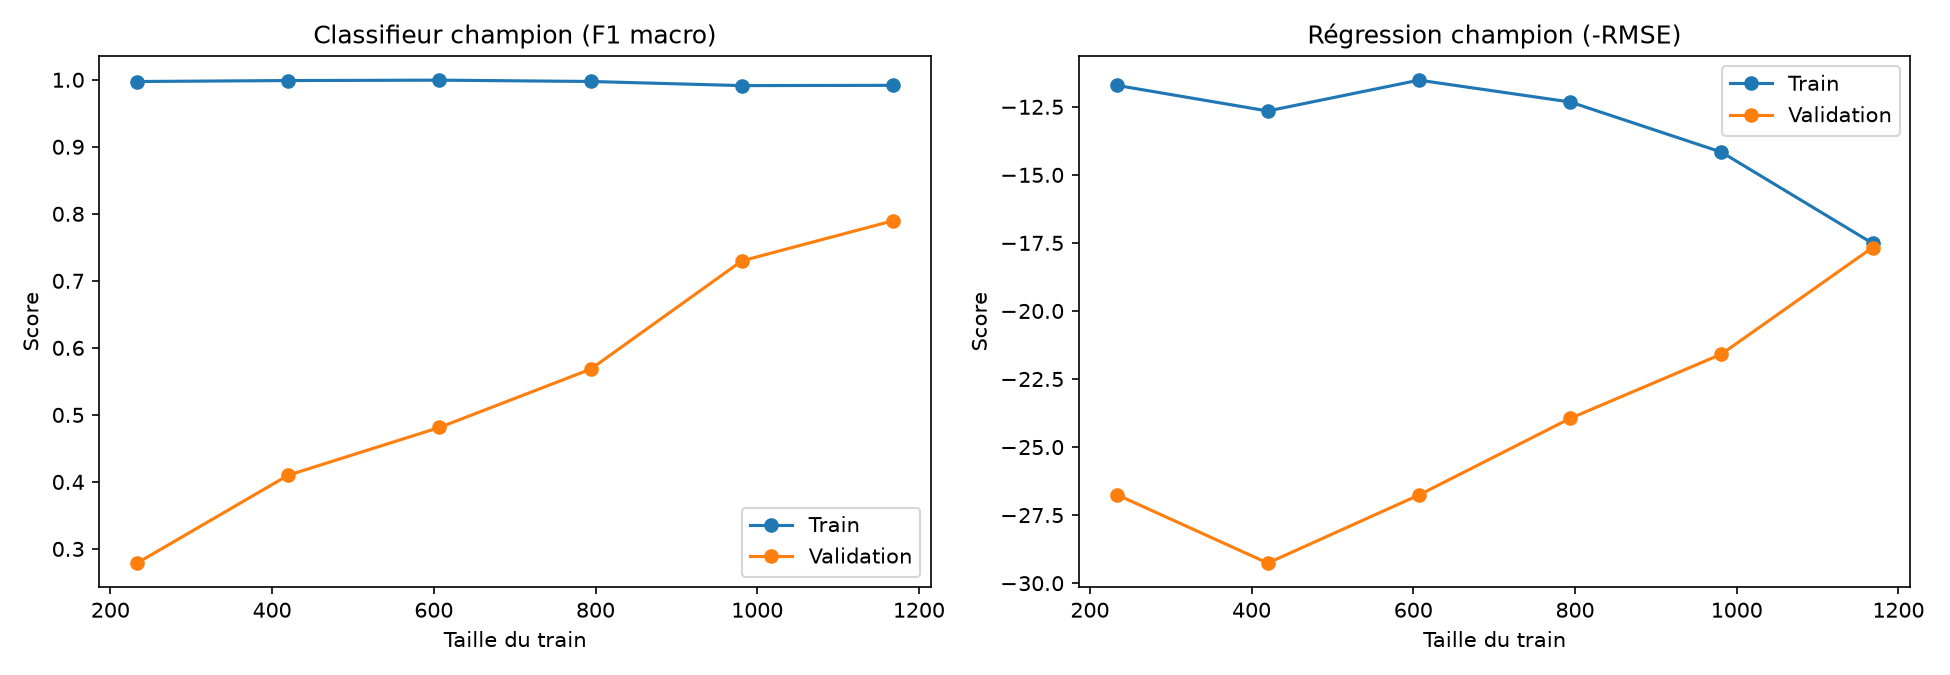

In [2]:
display(an.overfit_table())
train, _ = load_split(df)
an.plot_learning_curves(clf, reg, train, cfg.path('figures_dir')/'analysis_learning_curves.png')
display(Image(str(cfg.path('figures_dir')/'analysis_learning_curves.png'), width=900))

## 2. Erreurs
Les confusions se concentrent entre classes voisines (ex. Overweight I ↔ II), ce qui est cohérent avec une cible ordonnée issue de seuils d'IMC. Comparaison de A et C sur les mêmes individus :

In [3]:
display(an.errors_table())
display(an.errors_a_vs_c())

,y,A,n
0,Overweight_Level_I,Obesity_Type_I,10
1,Overweight_Level_I,Normal_Weight,9
2,Overweight_Level_II,Obesity_Type_I,8
3,Normal_Weight,Overweight_Level_II,8
4,Normal_Weight,Obesity_Type_I,8
5,Overweight_Level_I,Overweight_Level_II,8
6,Normal_Weight,Insufficient_Weight,7
7,Normal_Weight,Overweight_Level_I,7
8,Overweight_Level_II,Overweight_Level_I,7
9,Overweight_Level_II,Obesity_Type_II,6


C correct,False,True
A correct,,
False,113,24
True,371,119


## 3. Données synthétiques
Le champion est bien meilleur sur les lignes **proxy-synthétiques** que sur les lignes collectées : le score global est donc **optimiste** (heuristique, à interpréter avec prudence).

In [4]:
display(an.synthetic_split(clf, df))

,groupe,n,accuracy,f1_macro,accuracy_pm1
0,synthetique (proxy),470,0.855,0.728,0.926
1,collecte (proxy),157,0.561,0.402,0.758


## 4. Biais de genre
`Obesity_Type_II` est presque exclusivement masculin et `Obesity_Type_III` féminin. Les performances diffèrent selon le genre : le modèle peut apprendre `Gender` comme raccourci pour ces classes.

In [5]:
display(an.gender_crosstab(df))
display(an.gender_metrics(clf, df))

Gender,Female,Male
NObeyesdad,,
Insufficient_Weight,169,98
Normal_Weight,137,145
Overweight_Level_I,145,131
Overweight_Level_II,103,187
Obesity_Type_I,156,195
Obesity_Type_II,2,295
Obesity_Type_III,323,1


,Gender,n,accuracy,f1_macro
0,Female,296,0.831,0.767
1,Male,331,0.737,0.617


## 5. Facteurs clés
Importance par permutation **sur le test** (perte de F1 quand on mélange une variable) et coefficients standardisés de la régression (valeur absolue), agrégés par variable d'origine. L'importance par impureté n'existe que pour les forêts, pas pour le gradient boosting retenu comme champion.

In [6]:
imp = an.importances(clf, reg, df)
imp.to_csv(cfg.path('tables_dir')/'feature_importances.csv', index=False)
display(imp)

,variable,perm_importance_test,abs_coef_regression,rang_perm_importance_test,rang_abs_coef_regression
8,Age,0.3369,5.5620,1,5
6,Gender,0.1871,4.6901,2,8
9,FCVC,0.1155,4.2536,3,9
0,family_history_with_overweight,0.1103,20.2242,4,1
5,CALC,0.0924,4.7128,5,6
10,NCP,0.0903,0.4699,6,13
4,CAEC,0.0755,10.1920,7,3
12,FAF,0.0401,2.2717,8,10
11,CH2O,0.0361,0.8192,9,12
7,MTRANS,0.0298,12.2446,10,2


## 6. Synthèse, limites et recommandations
- **Fuite** : `Weight`/`Height` donnent presque la réponse (IMC) ; elles doivent être exclues dès que l'on veut prédire à partir des habitudes de vie.
- **Données synthétiques** : une grande part du jeu est générée par SMOTE ; les scores sont optimistes et un jeu de test 100 % collecté serait plus honnête.
- **Biais** : la quasi-exclusivité d'un genre dans certaines classes est un artefact ; l'équité du modèle n'est pas garantie.
- **Régression** : erreur d'environ 18 kg et hétéroscédasticité ; la classe dérivée du poids prédit est peu fiable.
- **Recommandations** : collecter davantage de données réelles, évaluer sur des données non synthétiques, et traiter l'IMC comme cible continue ordonnée plutôt que 7 classes indépendantes.